# EDA — Biais de genre dans Pokec (Ceska republika)

Pokec, réseau social slovaque. On analyse le sous-ensemble **Ceska republika** (~31K utilisateurs) — la région avec le biais de genre le plus fort du dataset (H->F/H->H = 4.59x).

In [134]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 11
DATA_DIR = Path('../data')
RESULTS_DIR = Path('../results')
RESULTS_DIR.mkdir(exist_ok=True)

In [135]:
# Chargement — filtre sur Ceska republika
df_profiles = pd.read_csv(DATA_DIR / 'soc-pokec-profiles.txt', sep='\t', header=None,
    na_values='null', usecols=[0, 3, 4], dtype=str).rename(columns={0: 'user_id', 3: 'gender', 4: 'region'})
df_profiles = df_profiles[df_profiles['region'].str.startswith('ceska republika', na=False)].copy()
df_profiles['user_id'] = pd.to_numeric(df_profiles['user_id'], errors='coerce').astype('Int32')
df_profiles['gender'] = pd.to_numeric(df_profiles['gender'], errors='coerce').astype('Int8')
df_profiles = df_profiles.set_index('user_id')

df_edges = pd.read_csv(DATA_DIR / 'soc-pokec-relationships.txt', sep='\t', header=None,
    names=['source', 'target'], dtype='int32')
node_set = set(df_profiles.index)
df_edges = df_edges[df_edges['source'].isin(node_set) & df_edges['target'].isin(node_set)].copy()
print(f"Graphe Ceska republika : {len(df_profiles):,} nœuds, {len(df_edges):,} arêtes dirigées")

Graphe Ceska republika : 31,298 nœuds, 69,120 arêtes dirigées


In [136]:
n_nodes, n_edges = len(df_profiles), len(df_edges)
density = n_edges / (n_nodes * (n_nodes - 1))
n_f = int((df_profiles['gender'] == 0).sum())
n_h = int((df_profiles['gender'] == 1).sum())

print(f"Nœuds : {n_nodes:,} | Arêtes : {n_edges:,} | Densité : {density:.2e} | Degré moyen : {n_edges/n_nodes:.1f}")
print(f"Genre : {n_f:,} femmes ({100*n_f/n_nodes:.1f}%) | {n_h:,} hommes ({100*n_h/n_nodes:.1f}%) >> quasi-équilibré")

Nœuds : 31,298 | Arêtes : 69,120 | Densité : 7.06e-05 | Degré moyen : 2.2
Genre : 17,835 femmes (57.0%) | 13,463 hommes (43.0%) >> quasi-équilibré


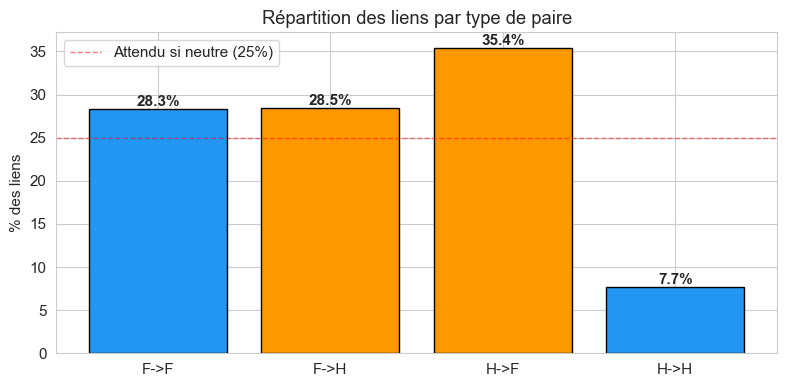

In [137]:
source_g = df_profiles.loc[df_edges['source'], 'gender'].values
target_g = df_profiles.loc[df_edges['target'], 'gender'].values
valid = pd.notna(source_g) & pd.notna(target_g)
sg, tg = np.array(source_g[valid], dtype='int8'), np.array(target_g[valid], dtype='int8')
pc = sg * 2 + tg
pair_counts = {'F->F': int((pc==0).sum()), 'F->H': int((pc==1).sum()),
               'H->F': int((pc==2).sum()), 'H->H': int((pc==3).sum())}
n_valid = int(valid.sum())
n_intra = pair_counts['F->F'] + pair_counts['H->H']
homophily = (n_intra / n_valid) / ((n_f/(n_f+n_h))**2 + (n_h/(n_f+n_h))**2)

fig, ax = plt.subplots(figsize=(8, 4))
pcts = {k: 100*v/n_valid for k, v in pair_counts.items()}
colors = ['#2196F3', '#FF9800', '#FF9800', '#2196F3']
bars = ax.bar(pcts.keys(), pcts.values(), color=colors, edgecolor='black')
ax.axhline(25, color='red', ls='--', lw=1, alpha=0.5, label='Attendu si neutre (25%)')
for b in bars: ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.3, f'{b.get_height():.1f}%', ha='center', fontweight='bold')
ax.set(ylabel='% des liens', title='Répartition des liens par type de paire')
ax.legend(); plt.tight_layout(); plt.show()

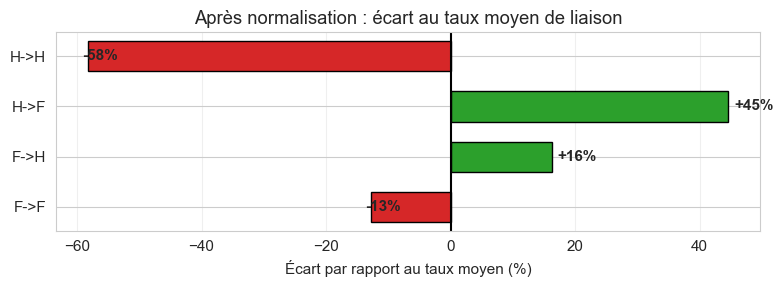

In [138]:
possible = {'F->F': n_f*(n_f-1), 'F->H': n_f*n_h, 'H->F': n_h*n_f, 'H->H': n_h*(n_h-1)}
rates = {k: 1e5 * pair_counts[k] / possible[k] for k in pair_counts}
avg_rate = 1e5 * sum(pair_counts.values()) / sum(possible.values())
ecart = {k: 100*(rates[k]/avg_rate - 1) for k in rates}

fig, ax = plt.subplots(figsize=(8, 3))
colors = ['#2ca02c' if v > 0 else '#d62728' for v in ecart.values()]
bars = ax.barh(list(ecart.keys()), list(ecart.values()), color=colors, edgecolor='black', height=0.6)
ax.axvline(0, color='black', lw=1.5)
for b in bars:
    val = b.get_width()
    ax.text(val + (1 if val >= 0 else -1), b.get_y()+b.get_height()/2, f'{val:+.0f}%', va='center', fontweight='bold')
ax.set(xlabel='Écart par rapport au taux moyen (%)', title='Après normalisation : écart au taux moyen de liaison')
ax.grid(axis='x', alpha=0.3); plt.tight_layout(); plt.show()

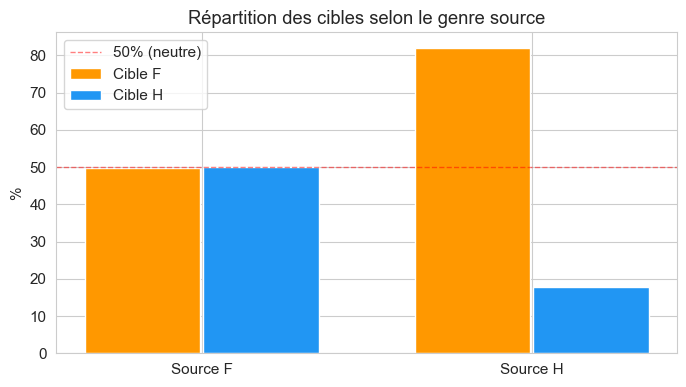

In [139]:
from_f = pair_counts['F->F'] + pair_counts['F->H']
from_h = pair_counts['H->F'] + pair_counts['H->H']
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(2)
ax.bar(x-0.18, [100*pair_counts['F->F']/from_f, 100*pair_counts['H->F']/from_h], 0.35, label='Cible F', color='#FF9800')
ax.bar(x+0.18, [100*pair_counts['F->H']/from_f, 100*pair_counts['H->H']/from_h], 0.35, label='Cible H', color='#2196F3')
ax.set_xticks(x, ['Source F', 'Source H'])
ax.axhline(50, color='red', ls='--', lw=1, alpha=0.5, label='50% (neutre)')
ax.set(ylabel='%', title='Répartition des cibles selon le genre source')
ax.legend(); plt.tight_layout(); plt.show()

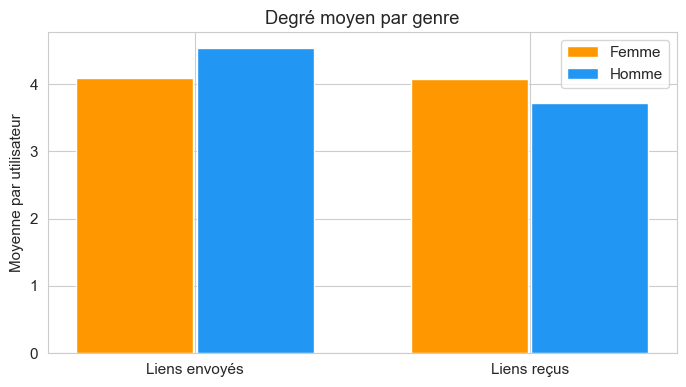

In [140]:
out_deg = df_edges['source'].value_counts()
in_deg = df_edges['target'].value_counts()
g = df_profiles['gender']
out_g, in_g = g.reindex(out_deg.index), g.reindex(in_deg.index)

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(2)
ax.bar(x-0.18, [out_deg[out_g==0].mean(), in_deg[in_g==0].mean()], 0.35, label='Femme', color='#FF9800')
ax.bar(x+0.18, [out_deg[out_g==1].mean(), in_deg[in_g==1].mean()], 0.35, label='Homme', color='#2196F3')
ax.set_xticks(x, ['Liens envoyés', 'Liens reçus'])
ax.set(ylabel='Moyenne par utilisateur', title='Degré moyen par genre')
ax.legend(); plt.tight_layout(); plt.show()

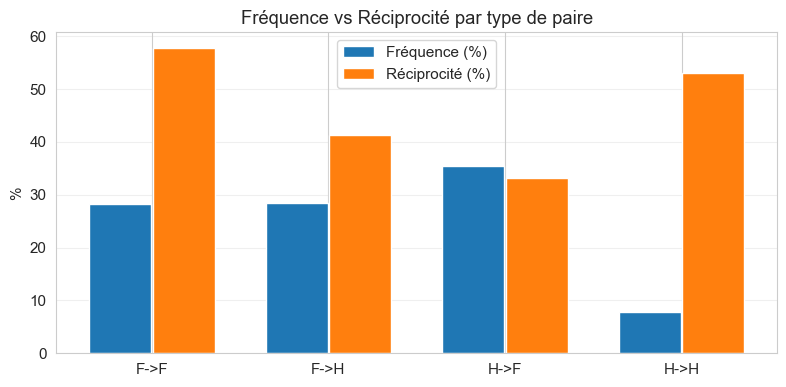

In [141]:
recip = df_edges.merge(df_edges.rename(columns={'source': 'target', 'target': 'source'}), on=['source', 'target'])
rg_s, rg_t = df_profiles.loc[recip['source'], 'gender'].values, df_profiles.loc[recip['target'], 'gender'].values
rv = pd.notna(rg_s) & pd.notna(rg_t)
rpc = np.array(rg_s[rv], dtype='int8') * 2 + np.array(rg_t[rv], dtype='int8')
recip_pct = {n: 100*(rpc==c).sum()/pair_counts[n] for n, c in [('F->F',0),('F->H',1),('H->F',2),('H->H',3)]}

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(4)
freq = [100*pair_counts[k]/n_valid for k in pair_counts]
rec = [recip_pct[k] for k in pair_counts]
ax.bar(x-0.18, freq, 0.35, label='Fréquence (%)', color='#1f77b4')
ax.bar(x+0.18, rec, 0.35, label='Réciprocité (%)', color='#ff7f0e')
ax.set_xticks(x, pair_counts.keys())
ax.set(ylabel='%', title='Fréquence vs Réciprocité par type de paire')
ax.legend(); ax.grid(axis='y', alpha=0.3); plt.tight_layout(); plt.show()

## Ce qu'on retient

Les 5 graphiques montrent un **biais de genre extrême** dans Pokec-Ceska republika (31K nœuds, 69K arêtes, 57% femmes) :

1. **Répartition des paires** — H->F = 35.4% domine massivement, H->H = 7.7% est quasiment inexistant (3x en-dessous de la ligne des 25%).
2. **Après normalisation** — H->F est +45% au-dessus du taux moyen, H->H -58% en-dessous. Le biais le plus fort de toutes les régions Pokec.
3. **Cibles par genre source** — Les femmes sont neutres (~50/50). Les hommes ciblent les femmes à ~82%. Le biais est presque exclusivement masculin.
4. **Degrés** — Les hommes envoient plus de liens (~4.5 vs ~4.1) mais en reçoivent moins (~3.7 vs ~4.1). Les femmes sont des cibles nettes.
5. **Fréquence vs Réciprocité** — H->F est le plus fréquent (35%) mais le moins réciproque (~33%). H->H est le moins fréquent (8%) mais le plus réciproque (~53%).